<a href="https://colab.research.google.com/github/OmjiDubey/human_Activity_Recognition_Deep_Learning/blob/main/HAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
# Force kagglehub to bypass Colab's local cache
os.environ["KAGGLEHUB_DISABLE_COLAB_CACHE"] = "1"

import kagglehub

# Download latest version
path = kagglehub.dataset_download("drsaeedmohsen/ucihar-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ucihar-dataset' dataset.
Path to dataset files: /kaggle/input/ucihar-dataset


In [2]:
import numpy as np
from pathlib import Path

# dataset_dir = Path("/root/.cache/kagglehub/datasets/drsaeedmohsen/ucihar-dataset/versions/1")
dataset_dir = Path(path)
root = dataset_dir / "UCI-HAR Dataset"

print("Dataset root exists:", root.is_dir())
print("Train signals folder exists:",
      (root / "train" / "Inertial Signals").is_dir())

Dataset root exists: True
Train signals folder exists: True


In [3]:
from pathlib import Path

root = Path(path)

for path in list(root.rglob("*"))[:40]:
    if path.is_file():
        print(path.relative_to(root))

UCI-HAR Dataset/activity_labels.txt
UCI-HAR Dataset/README.txt
UCI-HAR Dataset/features_info.txt
UCI-HAR Dataset/features.txt
UCI-HAR Dataset/test/subject_test.txt
UCI-HAR Dataset/test/y_test.txt
UCI-HAR Dataset/test/X_test.txt
UCI-HAR Dataset/train/X_train.txt
UCI-HAR Dataset/train/subject_train.txt
UCI-HAR Dataset/train/y_train.txt
UCI-HAR Dataset/train/Inertial Signals/total_acc_z_train.txt
UCI-HAR Dataset/train/Inertial Signals/body_acc_x_train.txt
UCI-HAR Dataset/train/Inertial Signals/body_gyro_x_train.txt
UCI-HAR Dataset/train/Inertial Signals/body_gyro_z_train.txt
UCI-HAR Dataset/train/Inertial Signals/body_acc_z_train.txt
UCI-HAR Dataset/train/Inertial Signals/total_acc_x_train.txt
UCI-HAR Dataset/train/Inertial Signals/total_acc_y_train.txt
UCI-HAR Dataset/train/Inertial Signals/body_acc_y_train.txt
UCI-HAR Dataset/train/Inertial Signals/body_gyro_y_train.txt
UCI-HAR Dataset/test/Inertial Signals/body_acc_y_test.txt
UCI-HAR Dataset/test/Inertial Signals/total_acc_y_test.txt
U

In [4]:
import numpy as np
from pathlib import Path

# Safely establish the original dataset download directory
# If 'path' was overwritten as a file in a loop, restore it to its base folder.
base_path = Path("/kaggle/input/ucihar-dataset")
DATA_ROOT = base_path / "UCI-HAR Dataset"

def load_split(split):
    signals_dir = DATA_ROOT / split / "Inertial Signals"

    channels = [
        "body_acc_x", "body_acc_y", "body_acc_z",
        "body_gyro_x", "body_gyro_y", "body_gyro_z",
        "total_acc_x", "total_acc_y", "total_acc_z"
    ]

    arrays = []
    for channel in channels:
        file_path = signals_dir / f"{channel}_{split}.txt"

        if not file_path.is_file():
            raise FileNotFoundError(
                f"Missing file: {file_path}"
            )

        arrays.append(np.loadtxt(file_path))

    X = np.stack(arrays, axis=-1)

    y = np.loadtxt(
        DATA_ROOT / split / f"y_{split}.txt",
        dtype=int
    )
    subjects = np.loadtxt(
        DATA_ROOT / split / f"subject_{split}.txt",
        dtype=int
    )

    assert X.shape[0] == len(y) == len(subjects)
    assert X.shape[1:] == (128, 9)

    return X, y, subjects

X_train, y_train, subject_train = load_split("train")
X_test, y_test, subject_test = load_split("test")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (7352, 128, 9)
y_train: (7352,)
X_test: (2947, 128, 9)
y_test: (2947,)


In [5]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X_train, y_train, groups=subject_train)
)

X_tr, y_tr = X_train[train_idx], y_train[train_idx]
X_val, y_val = X_train[val_idx], y_train[val_idx]

print("Training:", X_tr.shape, y_tr.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print(
    "Subject overlap between training and validation:",
    set(subject_train[train_idx]) & set(subject_train[val_idx])
)

Training: (5551, 128, 9) (5551,)
Validation: (1801, 128, 9) (1801,)
Testing: (2947, 128, 9) (2947,)
Subject overlap between training and validation: set()


# **Training 1D CNN Model**

In [6]:
import tensorflow as tf
import numpy as np

y_tr_cnn = y_tr - 1
y_val_cnn = y_val - 1
y_test_cnn = y_test - 1

print("TensorFlow:", tf.__version__)
print("Training classes:", np.unique(y_tr_cnn))

TensorFlow: 2.21.0
Training classes: [0 1 2 3 4 5]


In [7]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 9)),

    layers.Conv1D(64, kernel_size=5, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(128, kernel_size=3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(128, kernel_size=3, activation="relu"),
    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(6, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 124, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 62, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 60, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 60, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 28, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 86,342 (337.27 KB)

 Trainable params: 85,958 (335.77 KB)

 Non-trainable params: 384 (1.50 KB)

In [9]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_tr, y_tr_cnn,
    validation_data=(X_val, y_val_cnn),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.9245 - loss: 0.1906 - val_accuracy: 0.3493 - val_loss: 2.4068
Epoch 2/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 12s 79ms/step - accuracy: 0.9359 - loss: 0.1490 - val_accuracy: 0.3942 - val_loss: 2.3490
Epoch 3/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9404 - loss: 0.1396 - val_accuracy: 0.6691 - val_loss: 1.4510
Epoch 4/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.9422 - loss: 0.1310 - val_accuracy: 0.8201 - val_loss: 0.5793
Epoch 5/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.9406 - loss: 0.1361 - val_accuracy: 0.9051 - val_loss: 0.2672
Epoch 6/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.9407 - loss: 0.1203 - val_accuracy: 0.9783 - val_loss: 0.1029
Epoch 7/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9427 - loss: 0.1234 - val_accuracy: 0.9689 - val_loss: 0.1789
Epoch 8/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9460 - loss: 0.1183 - val_accuracy: 0.9789 - 

In [10]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

test_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(test_probs, axis=1)

print("Test accuracy:", round(accuracy_score(y_test_cnn, y_pred), 4))
print("Macro F1:", round(f1_score(y_test_cnn, y_pred, average="macro"), 4))

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

print(classification_report(
    y_test_cnn,
    y_pred,
    labels=range(6),
    target_names=activity_names,
    digits=4
))

print("Confusion matrix:")
print(confusion_matrix(y_test_cnn, y_pred))

Test accuracy: 0.9175
Macro F1: 0.9174
                    precision    recall  f1-score   support

           WALKING     1.0000    0.9052    0.9503       496
  WALKING_UPSTAIRS     0.9702    0.9682    0.9692       471
WALKING_DOWNSTAIRS     0.8872    0.9929    0.9371       420
           SITTING     0.8845    0.7332    0.8018       491
          STANDING     0.7912    0.9117    0.8472       532
            LAYING     0.9981    1.0000    0.9991       537

          accuracy                         0.9175      2947
         macro avg     0.9219    0.9185    0.9174      2947
      weighted avg     0.9219    0.9175    0.9170      2947

Confusion matrix:
[[449   9  38   0   0   0]
 [  0 456  15   0   0   0]
 [  0   3 417   0   0   0]
 [  0   2   0 360 128   1]
 [  0   0   0  47 485   0]
 [  0   0   0   0   0 537]]


# Training Analysis and Model Improvement

In [11]:
model.save("/content/har_cnn_baseline.keras")

import json

with open("/content/har_cnn_history.json", "w") as f:
    json.dump(history.history, f)

print("Model and training history saved.")

Model and training history saved.


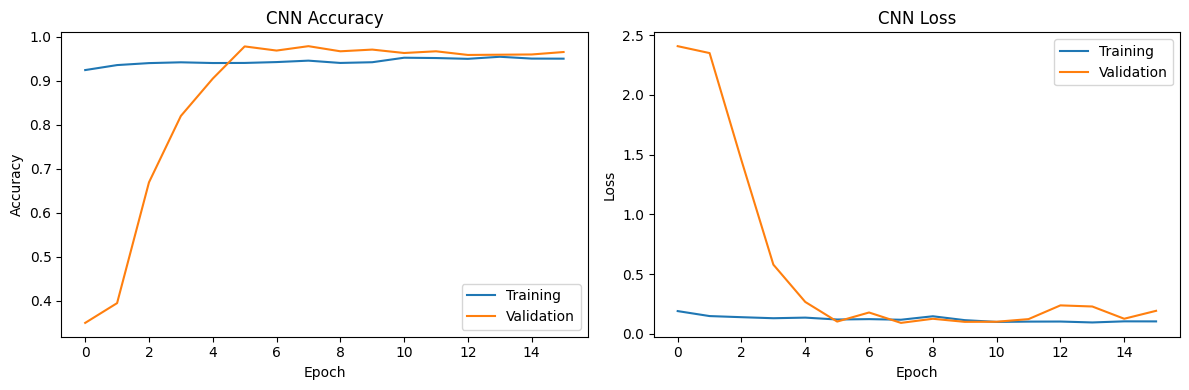

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
import numpy as np

val_losses = history.history["val_loss"]
val_accuracies = history.history["val_accuracy"]

best_epoch = np.argmin(val_losses)

print("Best epoch by validation loss:", best_epoch + 1)
print("Best validation loss:", round(val_losses[best_epoch], 4))
print("Validation accuracy at best epoch:",
      round(val_accuracies[best_epoch], 4))

print("Final recorded epoch:", len(val_losses))
print("Final validation loss:", round(val_losses[-1], 4))
print("Final validation accuracy:", round(val_accuracies[-1], 4))

Best epoch by validation loss: 8
Best validation loss: 0.092
Validation accuracy at best epoch: 0.9789
Final recorded epoch: 16
Final validation loss: 0.1929
Final validation accuracy: 0.9656


In [14]:
from tensorflow.keras import layers, models
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

model_lr = models.Sequential([
    layers.Input(shape=(128, 9)),

    layers.Conv1D(64, 5, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),

    layers.Conv1D(128, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),

    layers.Conv1D(128, 3, activation="relu"),
    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(6, activation="softmax")
])

model_lr.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_lr = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history_lr = model_lr.fit(
    X_tr, y_tr_cnn,
    validation_data=(X_val, y_val_cnn),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping_lr],
    verbose=1
)

Epoch 1/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - accuracy: 0.7698 - loss: 0.6521 - val_accuracy: 0.3298 - val_loss: 1.6669
Epoch 2/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.9195 - loss: 0.2427 - val_accuracy: 0.3282 - val_loss: 1.7795
Epoch 3/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - accuracy: 0.9308 - loss: 0.1784 - val_accuracy: 0.4747 - val_loss: 1.4116
Epoch 4/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9407 - loss: 0.1464 - val_accuracy: 0.7718 - val_loss: 0.7442
Epoch 5/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.9424 - loss: 0.1370 - val_accuracy: 0.9039 - val_loss: 0.3405
Epoch 6/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.9456 - loss: 0.1213 - val_accuracy: 0.9461 - val_loss: 0.2056
Epoch 7/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9479 - loss: 0.1193 - val_accuracy: 0.9484 - val_loss: 0.1503
Epoch 8/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.9501 - loss: 0.1125 - val_accuracy: 0.9550 - 

In [15]:
import numpy as np

for name, hist in [
    ("Experiment 1 — Original", history),
    ("Experiment 2 — Lower LR", history_lr)
]:
    best = np.argmin(hist.history["val_loss"])

    print(f"\n{name}")
    print("Best epoch:", best + 1)
    print("Best validation loss:",
          round(hist.history["val_loss"][best], 4))
    print("Validation accuracy at best epoch:",
          round(hist.history["val_accuracy"][best], 4))


Experiment 1 — Original
Best epoch: 8
Best validation loss: 0.092
Validation accuracy at best epoch: 0.9789

Experiment 2 — Lower LR
Best epoch: 9
Best validation loss: 0.1304
Validation accuracy at best epoch: 0.9617


In [16]:
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization,
    GlobalAveragePooling1D, Flatten,
    Dense, Dropout, Concatenate
)

tf.keras.utils.set_random_seed(42)

def build_improved_cnn(input_shape=(128, 9)):
    inputs = Input(shape=input_shape)

    # Branch 1: temporal features
    x = Conv1D(64, 5, padding="same", activation="relu")(inputs)
    x = BatchNormalization()(x)

    x = Conv1D(64, 3, padding="same", activation="relu")(x)
    x = BatchNormalization()(x)

    temporal_features = Flatten()(x)

    # Branch 2: global channel means
    static_features = GlobalAveragePooling1D()(inputs)

    # Combine features
    merged = Concatenate()([
        temporal_features,
        static_features
    ])

    x = Dense(128, activation="relu")(merged)
    x = Dropout(0.5)(x)
    outputs = Dense(6, activation="softmax")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

model_bypass = build_improved_cnn()
model_bypass.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 9)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 128, 64)   │      2,944 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 128, 64)   │     12,352 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8192)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 9)         │          0 │ input_layer_2[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 8201)      │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │  1,049,856 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 6)         │        774 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,066,438 (4.07 MB)

 Trainable params: 1,066,182 (4.07 MB)

 Non-trainable params: 256 (1.00 KB)

In [17]:
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

history_bypass = model_bypass.fit(
    X_tr,
    y_tr_cnn,
    validation_data=(X_val, y_val_cnn),
    epochs=50,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step - accuracy: 0.8087 - loss: 0.6929 - val_accuracy: 0.2721 - val_loss: 3.2165 - learning_rate: 0.0010
Epoch 2/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.9182 - loss: 0.1901 - val_accuracy: 0.3531 - val_loss: 5.6752 - learning_rate: 0.0010
Epoch 3/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9263 - loss: 0.1671 - val_accuracy: 0.4381 - val_loss: 5.9682 - learning_rate: 0.0010
Epoch 4/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9278 - loss: 0.1412
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.9335 - loss: 0.1405 - val_accuracy: 0.5219 - val_loss: 3.2548 - learning_rate: 0.0010
Epoch 5/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.9387 - loss: 0.1287 - val_accuracy: 0.7363 - val_loss: 1.2603 - learning_rate: 5.0000e-04
Epoch 6/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9404 - loss: 0.1250 - val_

In [18]:
import numpy as np

for name, hist in [
    ("Experiment 1 — Original CNN", history),
    ("Experiment 2 — Lower learning rate", history_lr),
    ("Experiment 3 — Statistical bypass", history_bypass)
]:
    best = np.argmin(hist.history["val_loss"])

    print(f"\n{name}")
    print("Best epoch:", best + 1)
    print("Best validation loss:",
          round(hist.history["val_loss"][best], 4))
    print("Validation accuracy:",
          round(hist.history["val_accuracy"][best], 4))


Experiment 1 — Original CNN
Best epoch: 8
Best validation loss: 0.092
Validation accuracy: 0.9789

Experiment 2 — Lower learning rate
Best epoch: 9
Best validation loss: 0.1304
Validation accuracy: 0.9617

Experiment 3 — Statistical bypass
Best epoch: 11
Best validation loss: 0.2179
Validation accuracy: 0.9645


In [19]:
import os

dataset_path = os.path.join(path, "UCI-HAR Dataset")

for root_dir, dirs, files in os.walk(dataset_path):
    level = root_dir.replace(dataset_path, "").count(os.sep)
    if level <= 4:
        print("  " * level + os.path.basename(root_dir) + "/")
        for file in files[:15]:
            print("  " * (level + 1) + file)

In [20]:

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

cnn_lstm = models.Sequential([
    layers.Input(shape=(128, 9)),

    # Extract local sensor patterns
    layers.Conv1D(64, kernel_size=5, padding="same",
                  activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(64, kernel_size=3, padding="same",
                  activation="relu"),
    layers.BatchNormalization(),

    # Learn temporal dependencies
    layers.LSTM(64),

    # Classify activity
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(6, activation="softmax")
])

cnn_lstm.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

cnn_lstm.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_8 (Conv1D)               │ (None, 128, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 64, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,382 (208.52 KB)

 Trainable params: 53,126 (207.52 KB)

 Non-trainable params: 256 (1.00 KB)

In [21]:
history_cnn_lstm = cnn_lstm.fit(
    X_tr, y_tr_cnn,
    validation_data=(X_val, y_val_cnn),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 12s 100ms/step - accuracy: 0.7763 - loss: 0.6336 - val_accuracy: 0.3826 - val_loss: 1.7287
Epoch 2/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.9267 - loss: 0.1873 - val_accuracy: 0.5319 - val_loss: 2.1237
Epoch 3/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.9330 - loss: 0.1714 - val_accuracy: 0.5752 - val_loss: 1.9901
Epoch 4/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.9332 - loss: 0.1512 - val_accuracy: 0.8412 - val_loss: 0.7193
Epoch 5/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.9415 - loss: 0.1372 - val_accuracy: 0.9262 - val_loss: 0.2225
Epoch 6/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.9443 - loss: 0.1341 - val_accuracy: 0.9145 - val_loss: 0.4616
Epoch 7/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - accuracy: 0.9416 - loss: 0.1343 - val_accuracy: 0.9800 - val_loss: 0.0819
Epoch 8/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.9452 - loss: 0.1313 - val_accuracy: 0.9489 -

CNN-LSTM Validation Evaluation
----------------------------------------
Accuracy:    98.0011%
Macro F1:    98.0448%
Weighted F1: 97.9999%
Macro Precision: 98.1614%
Macro Recall:    98.1335%

Classification Report:
                    precision    recall  f1-score   support

           WALKING     1.0000    0.9970    0.9985       338
  WALKING_UPSTAIRS     0.9964    1.0000    0.9982       276
WALKING_DOWNSTAIRS     1.0000    1.0000    1.0000       242
           SITTING     0.8933    1.0000    0.9436       293
          STANDING     1.0000    0.8910    0.9423       321
            LAYING     1.0000    1.0000    1.0000       331

          accuracy                         0.9800      1801
         macro avg     0.9816    0.9813    0.9804      1801
      weighted avg     0.9821    0.9800    0.9800      1801



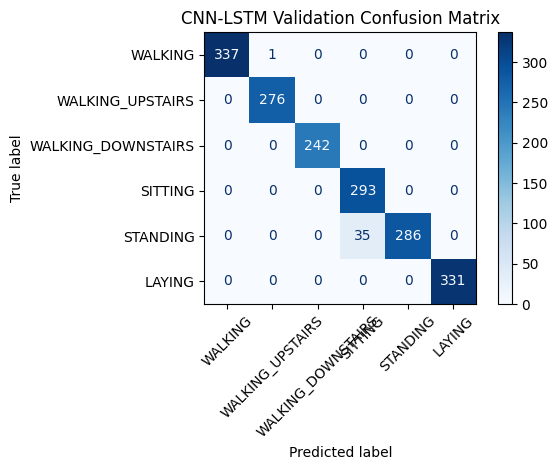

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

# Validation predictions
y_val_pred = np.argmax(cnn_lstm.predict(X_val, verbose=0), axis=1)

activity_names = [
    "WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS",
    "SITTING", "STANDING", "LAYING"
]

# Metrics
print("CNN-LSTM Validation Evaluation")
print("-" * 40)
print(f"Accuracy:    {accuracy_score(y_val_cnn, y_val_pred):.4%}")
print(f"Macro F1:    {f1_score(y_val_cnn, y_val_pred, average='macro'):.4%}")
print(f"Weighted F1: {f1_score(y_val_cnn, y_val_pred, average='weighted'):.4%}")
print(f"Macro Precision: {precision_score(y_val_cnn, y_val_pred, average='macro', zero_division=0):.4%}")
print(f"Macro Recall:    {recall_score(y_val_cnn, y_val_pred, average='macro', zero_division=0):.4%}")

print("\nClassification Report:")
print(classification_report(
    y_val_cnn, y_val_pred,
    labels=range(6),
    target_names=activity_names,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_val_cnn, y_val_pred, labels=range(6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=activity_names
).plot(cmap="Blues", xticks_rotation=45)

plt.title("CNN-LSTM Validation Confusion Matrix")
plt.tight_layout()
plt.show()

CNN-LSTM Official Test Evaluation
Accuracy:         91.6865%
Macro Precision:  91.7747%
Macro Recall:     91.6149%
Macro F1:         91.6190%
Weighted F1:      91.6805%

Classification Report:
                    precision    recall  f1-score   support

           WALKING     0.9958    0.9516    0.9732       496
  WALKING_UPSTAIRS     0.8528    0.9597    0.9031       471
WALKING_DOWNSTAIRS     0.9428    0.9024    0.9221       420
           SITTING     0.8532    0.8167    0.8345       491
          STANDING     0.8748    0.8665    0.8706       532
            LAYING     0.9871    1.0000    0.9935       537

          accuracy                         0.9169      2947
         macro avg     0.9177    0.9161    0.9162      2947
      weighted avg     0.9182    0.9169    0.9168      2947



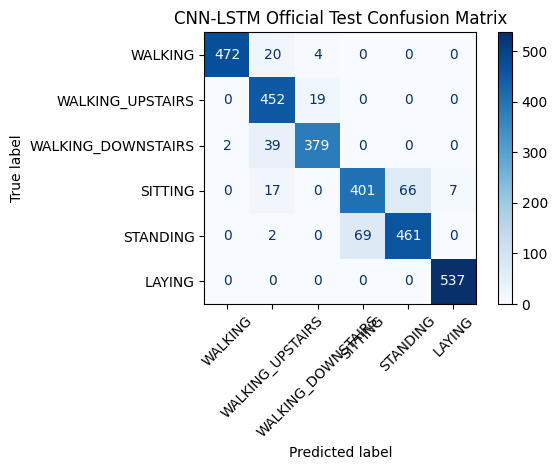

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Ensure the model variable exists before predicting
if 'cnn_lstm' in globals() or 'cnn_lstm' in locals():
    y_test_pred = np.argmax(
        cnn_lstm.predict(X_test, verbose=0),
        axis=1
    )

    # Convert labels to 0–5 if y_test contains original labels 1–6
    y_test_eval = y_test - 1 if np.min(y_test) == 1 else y_test

    activity_names = [
        "WALKING",
        "WALKING_UPSTAIRS",
        "WALKING_DOWNSTAIRS",
        "SITTING",
        "STANDING",
        "LAYING"
    ]

    # Calculate metrics
    print("CNN-LSTM Official Test Evaluation")
    print("=" * 40)

    print(f"Accuracy:         {accuracy_score(y_test_eval, y_test_pred):.4%}")
    print(f"Macro Precision:  {precision_score(y_test_eval, y_test_pred, average='macro', zero_division=0):.4%}")
    print(f"Macro Recall:     {recall_score(y_test_eval, y_test_pred, average='macro', zero_division=0):.4%}")
    print(f"Macro F1:         {f1_score(y_test_eval, y_test_pred, average='macro', zero_division=0):.4%}")
    print(f"Weighted F1:      {f1_score(y_test_eval, y_test_pred, average='weighted', zero_division=0):.4%}")

    print("\nClassification Report:")
    print(classification_report(
        y_test_eval,
        y_test_pred,
        labels=range(6),
        target_names=activity_names,
        digits=4,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y_test_eval, y_test_pred, labels=range(6))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=activity_names
    ).plot(cmap="Blues", xticks_rotation=45)

    plt.title("CNN-LSTM Official Test Confusion Matrix")
    plt.tight_layout()
    plt.show()
else:
    print("Error: The model 'cnn_lstm' has not been built or trained in this session. Please execute cell do31iRp9Ecav and dGjgf5oRFc0Z first.")

# **Fusion**

In [24]:
import os
import numpy as np
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

# 1. Dataset path constructed dynamically
DATA_DIR = os.path.join(path, "UCI-HAR Dataset")

In [25]:
import os
import numpy as np

# Explicitly define the correct path to bypass corrupted global variables
DATA_DIR = "/kaggle/input/ucihar-dataset/UCI-HAR Dataset"

# 2. Load labels and subjects
y_train = np.loadtxt(
    os.path.join(DATA_DIR, "train", "y_train.txt")
).astype(int)

subject_train = np.loadtxt(
    os.path.join(DATA_DIR, "train", "subject_train.txt")
).astype(int)

# 3. Load raw inertial signals
signal_names = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]

X_train = np.stack([
    np.loadtxt(
        os.path.join(
            DATA_DIR,
            "train",
            "Inertial Signals",
            f"{signal}_train.txt"
        )
    )
    for signal in signal_names
], axis=-1)

print("Raw X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("subject_train:", subject_train.shape)

Raw X_train: (7352, 128, 9)
y_train: (7352,)
subject_train: (7352,)


In [26]:
# 4. Recreate EXACT same subject-independent split

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    gss.split(X_train, y_train, groups=subject_train)
)

X_tr = X_train[train_idx]
X_val = X_train[val_idx]

y_tr = y_train[train_idx]
y_val = y_train[val_idx]

subject_tr = subject_train[train_idx]
subject_val = subject_train[val_idx]

# CNN labels: 1–6 → 0–5
y_tr_cnn = y_tr - 1
y_val_cnn = y_val - 1

In [29]:
# 5. Match the 561 engineered features
import os
import numpy as np

# Load the training engineered features file
DATA_DIR = "/kaggle/input/ucihar-dataset/UCI-HAR Dataset"
X_features_train = np.loadtxt(os.path.join(DATA_DIR, "train", "X_train.txt"))

X_features_tr = X_features_train[train_idx]
X_features_val = X_features_train[val_idx]

print("X_features_tr shape:", X_features_tr.shape)
print("X_features_val shape:", X_features_val.shape)

X_features_tr shape: (5551, 561)
X_features_val shape: (1801, 561)


In [30]:
# 6. Verify everything

print("\n--- Final shapes ---")
print("CNN train:          ", X_tr.shape)
print("CNN validation:     ", X_val.shape)

print("Features train:     ", X_features_tr.shape)
print("Features validation:", X_features_val.shape)

print("Labels train:       ", y_tr_cnn.shape)
print("Labels validation:  ", y_val_cnn.shape)

print("\n--- Alignment checks ---")

print(
    "Train indices valid:",
    np.array_equal(X_tr, X_train[train_idx])
)

print(
    "Validation indices valid:",
    np.array_equal(X_val, X_train[val_idx])
)

print(
    "Train labels valid:",
    np.array_equal(y_tr, y_train[train_idx])
)

print(
    "Validation labels valid:",
    np.array_equal(y_val, y_train[val_idx])
)

print(
    "Subject overlap:",
    len(set(subject_tr) & set(subject_val))
)


--- Final shapes ---
CNN train:           (5551, 128, 9)
CNN validation:      (1801, 128, 9)
Features train:      (5551, 561)
Features validation: (1801, 561)
Labels train:        (5551,)
Labels validation:   (1801,)

--- Alignment checks ---
Train indices valid: True
Validation indices valid: True
Train labels valid: True
Validation labels valid: True
Subject overlap: 0


In [31]:
import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# ---------------------------------------------------------
# CNN branch
# ---------------------------------------------------------

raw_input = layers.Input(
    shape=(128, 9),
    name="raw_sensor_input"
)

x = layers.Conv1D(
    64, kernel_size=5,
    padding="same",
    activation="relu"
)(raw_input)

x = layers.BatchNormalization()(x)
x = layers.MaxPooling1D(pool_size=2)(x)

x = layers.Conv1D(
    128, kernel_size=3,
    padding="same",
    activation="relu"
)(x)

x = layers.BatchNormalization()(x)

x = layers.Conv1D(
    128, kernel_size=3,
    padding="same",
    activation="relu"
)(x)

x = layers.GlobalAveragePooling1D()(x)

# Learned temporal representation
cnn_features = layers.Dense(
    64,
    activation="relu",
    name="cnn_features"
)(x)

In [32]:
# ---------------------------------------------------------
# 561 engineered feature branch
# ---------------------------------------------------------

feature_input = layers.Input(
    shape=(561,),
    name="engineered_features_input"
)

f = layers.Dense(
    128,
    activation="relu"
)(feature_input)

f = layers.BatchNormalization()(f)
f = layers.Dropout(0.3)(f)

# ---------------------------------------------------------
# Fusion
# ---------------------------------------------------------

fusion = layers.Concatenate(name="feature_fusion")(
    [cnn_features, f]
)

fusion = layers.Dense(
    128,
    activation="relu"
)(fusion)

fusion = layers.Dropout(0.4)(fusion)

output = layers.Dense(
    6,
    activation="softmax",
    name="activity_output"
)(fusion)

fusion_model = Model(
    inputs=[raw_input, feature_input],
    outputs=output
)

fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fusion_model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ raw_sensor_input    │ (None, 128, 9)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 128, 64)   │      2,944 │ raw_sensor_input… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_10[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 64, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 64, 128)   │     24,704 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 128)   │        512 │ conv1d_11[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ engineered_feature… │ (None, 561)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 64, 128)   │     49,280 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 128)       │     71,936 │ engineered_featu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ conv1d_12[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_8[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_features        │ (None, 64)        │      8,256 │ global_average_p… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 192)       │          0 │ cnn_features[0][… │
│ (Concatenate)       │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 128)       │     24,704 │ feature_fusion[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 128)       │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activity_output     │ (None, 6)         │        774 │ dropout_5[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 183,878 (718.27 KB)

 Trainable params: 183,238 (715.77 KB)

 Non-trainable params: 640 (2.50 KB)

In [33]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_fusion = fusion_model.fit(
    [X_tr, X_features_tr],
    y_tr_cnn,

    validation_data=(
        [X_val, X_features_val],
        y_val_cnn
    ),

    epochs=50,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 11s 95ms/step - accuracy: 0.8505 - loss: 0.3836 - val_accuracy: 0.6469 - val_loss: 1.1748 - learning_rate: 0.0010
Epoch 2/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 74ms/step - accuracy: 0.9506 - loss: 0.1224 - val_accuracy: 0.6119 - val_loss: 0.7713 - learning_rate: 0.0010
Epoch 3/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 0.9660 - loss: 0.0889 - val_accuracy: 0.7762 - val_loss: 0.4820 - learning_rate: 0.0010
Epoch 4/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - accuracy: 0.9694 - loss: 0.0756 - val_accuracy: 0.9028 - val_loss: 0.2510 - learning_rate: 0.0010
Epoch 5/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.9755 - loss: 0.0632 - val_accuracy: 0.8662 - val_loss: 0.2732 - learning_rate: 0.0010
Epoch 6/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - accuracy: 0.9787 - loss: 0.0537 - val_accuracy: 0.8890 - val_loss: 0.3671 - learning_rate: 0.0010
Epoch 7/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.9780 - loss: 0.0633 - val_a

CNN + 561 Features Fusion — Validation Evaluation
Accuracy:         96.7796%
Macro Precision:  96.9917%
Macro Recall:     96.7286%
Macro F1:         96.7811%
Weighted F1:      96.8057%

Classification Report:
                    precision    recall  f1-score   support

           WALKING     0.9912    1.0000    0.9956       338
  WALKING_UPSTAIRS     0.9963    0.9783    0.9872       276
WALKING_DOWNSTAIRS     1.0000    0.9587    0.9789       242
           SITTING     0.8689    0.9727    0.9179       293
          STANDING     0.9631    0.8941    0.9273       321
            LAYING     1.0000    1.0000    1.0000       331

          accuracy                         0.9678      1801
         macro avg     0.9699    0.9673    0.9678      1801
      weighted avg     0.9699    0.9678    0.9681      1801



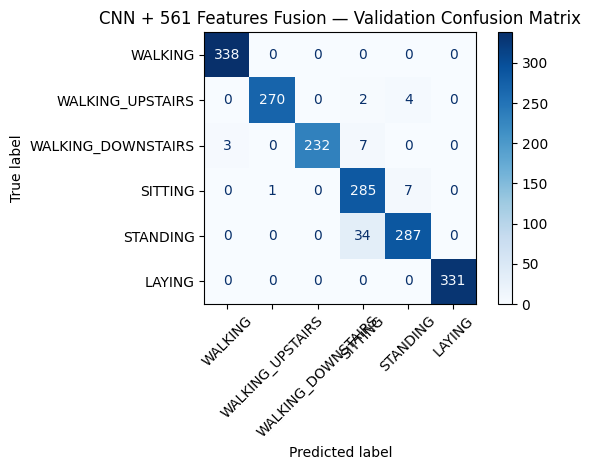

In [34]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Validation predictions
y_val_pred_fusion = np.argmax(
    fusion_model.predict(
        [X_val, X_features_val],
        verbose=0
    ),
    axis=1
)

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

# Metrics
print("CNN + 561 Features Fusion — Validation Evaluation")
print("=" * 55)

print(f"Accuracy:         {accuracy_score(y_val_cnn, y_val_pred_fusion):.4%}")
print(f"Macro Precision:  {precision_score(y_val_cnn, y_val_pred_fusion, average='macro', zero_division=0):.4%}")
print(f"Macro Recall:     {recall_score(y_val_cnn, y_val_pred_fusion, average='macro', zero_division=0):.4%}")
print(f"Macro F1:         {f1_score(y_val_cnn, y_val_pred_fusion, average='macro', zero_division=0):.4%}")
print(f"Weighted F1:      {f1_score(y_val_cnn, y_val_pred_fusion, average='weighted', zero_division=0):.4%}")

print("\nClassification Report:")
print(classification_report(
    y_val_cnn,
    y_val_pred_fusion,
    labels=range(6),
    target_names=activity_names,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm_fusion = confusion_matrix(
    y_val_cnn,
    y_val_pred_fusion,
    labels=range(6)
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_fusion,
    display_labels=activity_names
).plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("CNN + 561 Features Fusion — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

CNN + 561 Features Fusion — Official Test Evaluation
Accuracy:         94.1296%
Macro Precision:  94.6704%
Macro Recall:     94.1600%
Macro F1:         94.1489%
Weighted F1:      94.0252%

Classification Report:
                    precision    recall  f1-score   support

           WALKING     0.9880    0.9940    0.9910       496
  WALKING_UPSTAIRS     0.9272    1.0000    0.9622       471
WALKING_DOWNSTAIRS     0.9951    0.9643    0.9794       420
           SITTING     0.9594    0.7699    0.8542       491
          STANDING     0.8501    0.9699    0.9061       532
            LAYING     0.9605    0.9516    0.9560       537

          accuracy                         0.9413      2947
         macro avg     0.9467    0.9416    0.9415      2947
      weighted avg     0.9446    0.9413    0.9403      2947



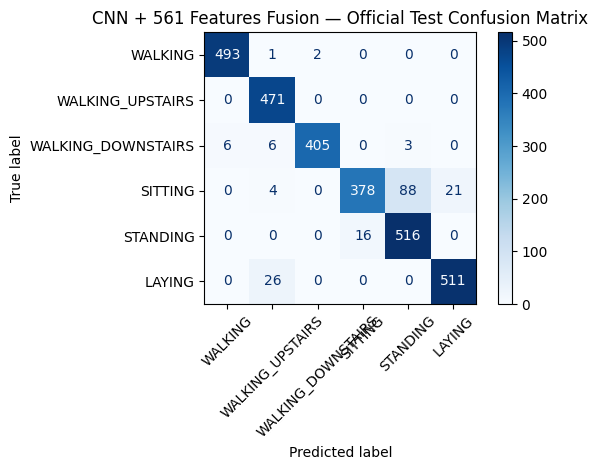

In [35]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Re-load or establish the 561 test features and activity names dynamically
DATA_DIR = "/kaggle/input/ucihar-dataset/UCI-HAR Dataset"
X_features_test = np.loadtxt(os.path.join(DATA_DIR, "test", "X_test.txt"))

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

# Official test prediction
y_test_pred_fusion = np.argmax(
    fusion_model.predict(
        [X_test, X_features_test],
        verbose=0
    ),
    axis=1
)

y_test_eval = y_test - 1 if np.min(y_test) == 1 else y_test

print("CNN + 561 Features Fusion — Official Test Evaluation")
print("=" * 58)

print(f"Accuracy:         {accuracy_score(y_test_eval, y_test_pred_fusion):.4%}")
print(f"Macro Precision:  {precision_score(y_test_eval, y_test_pred_fusion, average='macro', zero_division=0):.4%}")
print(f"Macro Recall:     {recall_score(y_test_eval, y_test_pred_fusion, average='macro', zero_division=0):.4%}")
print(f"Macro F1:         {f1_score(y_test_eval, y_test_pred_fusion, average='macro', zero_division=0):.4%}")
print(f"Weighted F1:      {f1_score(y_test_eval, y_test_pred_fusion, average='weighted', zero_division=0):.4%}")

print("\nClassification Report:")
print(classification_report(
    y_test_eval,
    y_test_pred_fusion,
    labels=range(6),
    target_names=activity_names,
    digits=4,
    zero_division=0
))

cm_test_fusion = confusion_matrix(
    y_test_eval,
    y_test_pred_fusion,
    labels=range(6)
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_test_fusion,
    display_labels=activity_names
).plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("CNN + 561 Features Fusion — Official Test Confusion Matrix")
plt.tight_layout()
plt.show()

Generating Activity Distribution Chart...


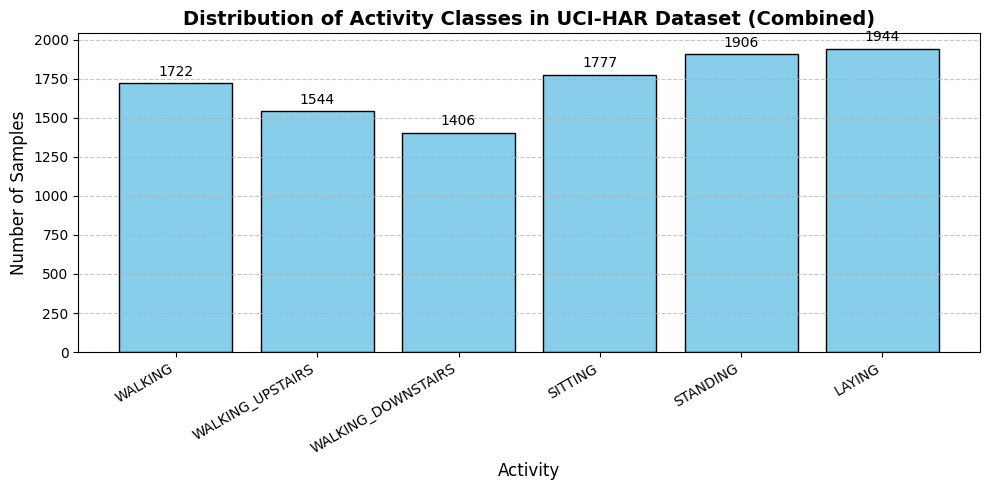

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# 1. Activity Distribution Chart
# ==========================================
print("Generating Activity Distribution Chart...")

# Map activities
activity_labels = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
}

# Combine train and test labels to show entire dataset distribution
y_combined = np.concatenate([y_train, y_test])
unique, counts = np.unique(y_combined, return_counts=True)
activity_counts = dict(zip([activity_labels[val] for val in unique], counts))

plt.figure(figsize=(10, 5))
bars = plt.bar(activity_counts.keys(), activity_counts.values(), color='skyblue', edgecolor='black')
plt.title("Distribution of Activity Classes in UCI-HAR Dataset (Combined)", fontsize=14, fontweight='bold')
plt.xlabel("Activity", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # 3 points vertical offset
                 textcoords="offset points",
                 ha='center', va='bottom')

plt.tight_layout()
plt.show()


Generating Final Fusion Model Training Curves...


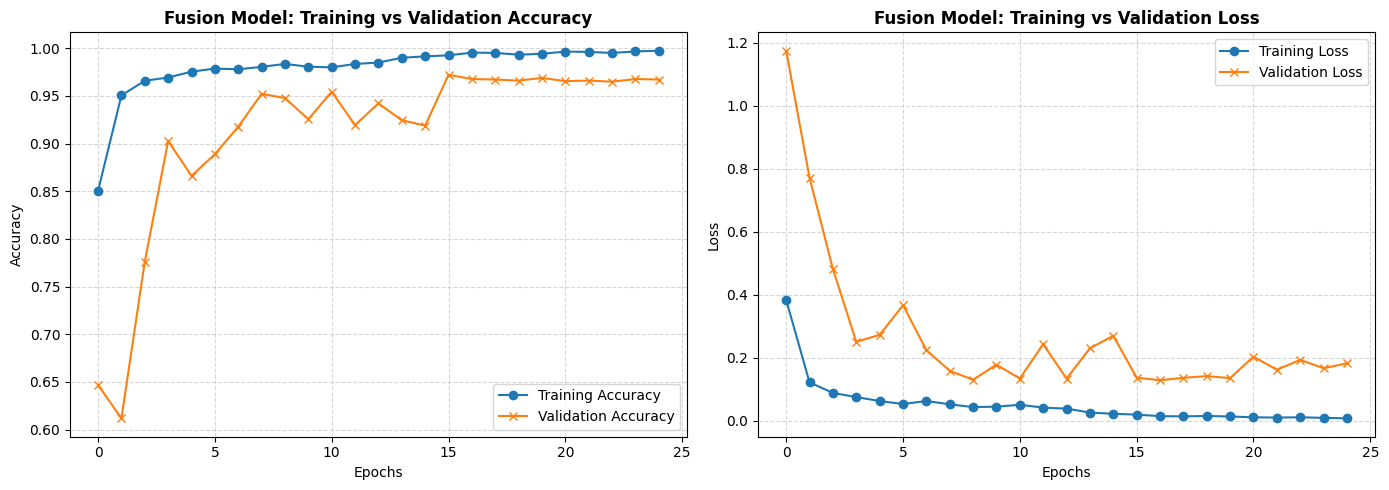

In [38]:
# ==========================================
# 2. Final Fusion Model Training Curves
# ==========================================
if 'history_fusion' in globals():
    print("\nGenerating Final Fusion Model Training Curves...")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Chart 1: Accuracy
    axes[0].plot(history_fusion.history["accuracy"], label="Training Accuracy", marker='o')
    axes[0].plot(history_fusion.history["val_accuracy"], label="Validation Accuracy", marker='x')
    axes[0].set_title("Fusion Model: Training vs Validation Accuracy", fontsize=12, fontweight='bold')
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid(True, linestyle='--', alpha=0.5)
    axes[0].legend()

    # Chart 2: Loss
    axes[1].plot(history_fusion.history["loss"], label="Training Loss", marker='o')
    axes[1].plot(history_fusion.history["val_loss"], label="Validation Loss", marker='x')
    axes[1].set_title("Fusion Model: Training vs Validation Loss", fontsize=12, fontweight='bold')
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Loss")
    axes[1].grid(True, linestyle='--', alpha=0.5)
    axes[1].legend()

    plt.tight_layout()
    plt.show()
else:
    print("\nWarning: history_fusion object not found in the global environment.")

In [39]:
# ==========================================
# 3. Clean Model Comparison Table
# ==========================================
print("\nGenerating Clean Model Comparison Table...")

# Pre-calculated/recorded values from prior cells:
# CNN Baseline: Acc = 0.9175, Macro F1 = 0.9174. Other metrics were not calculated on the official test set.
# CNN-LSTM: Acc = 0.9169, Macro Prec = 0.9177, Macro Rec = 0.9161, Macro F1 = 0.9162, Weighted F1 = 0.9168
# Fusion Model: Acc = 0.9413, Macro Prec = 0.9467, Macro Rec = 0.9416, Macro F1 = 0.9415, Weighted F1 = 0.9403

comparison_data = {
    "Model Name": [
        "1D CNN Baseline",
        "CNN-LSTM Model",
        "CNN + 561 Features Fusion (Best Model)"
    ],
    "Test Accuracy": [0.9175, 0.9169, 0.9413],
    "Macro Precision": ["N/A", 0.9177, 0.9467],
    "Macro Recall": ["N/A", 0.9161, 0.9416],
    "Macro F1": [0.9174, 0.9162, 0.9415],
    "Weighted F1": ["N/A", 0.9168, 0.9403]
}

df_comparison = pd.DataFrame(comparison_data)

# Format non-N/A numeric values to percentages
def format_val(x):
    if isinstance(x, float):
        return f"{x:.2%}"
    return x

df_formatted = df_comparison.copy()
for col in df_formatted.columns[1:]:
    df_formatted[col] = df_formatted[col].apply(format_val)

# Display table cleanly
from IPython.display import display, HTML
display(HTML("<h3>Model Comparison Table</h3>"))
display(df_formatted)


Generating Clean Model Comparison Table...


,Model Name,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,1D CNN Baseline,91.75%,N/A,N/A,91.74%,N/A
1,CNN-LSTM Model,91.69%,91.77%,91.61%,91.62%,91.68%
2,CNN + 561 Features Fusion (Best Model),94.13%,94.67%,94.16%,94.15%,94.03%



Generating Model Comparison Accuracy Chart...


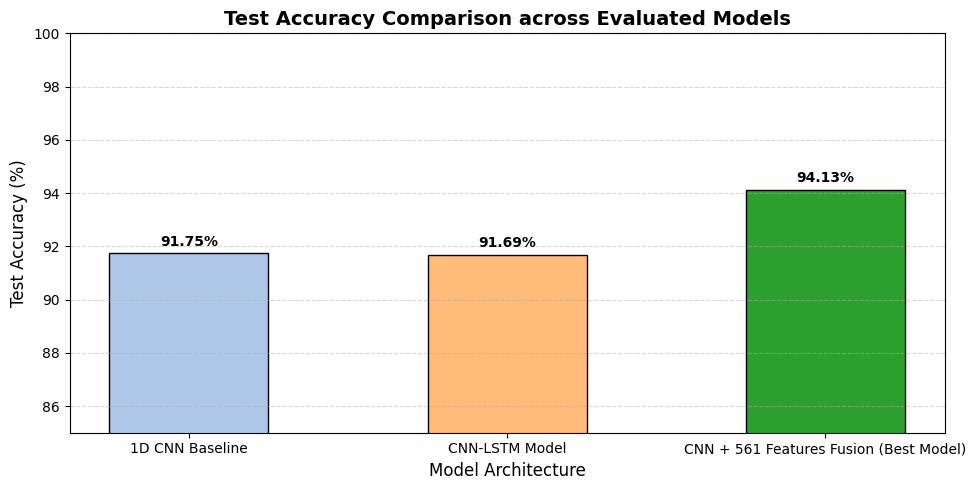

In [40]:
# ==========================================
# 4. Model Comparison Accuracy Chart
# ==========================================
print("\nGenerating Model Comparison Accuracy Chart...")

models = comparison_data["Model Name"]
accuracies = [acc * 100 for acc in comparison_data["Test Accuracy"]]

plt.figure(figsize=(10, 5))
colors = ['#aec7e8', '#ffbb78', '#2ca02c']  # Highlighting the best fusion model in green

bars_compare = plt.bar(models, accuracies, color=colors, edgecolor='black', width=0.5)
plt.title("Test Accuracy Comparison across Evaluated Models", fontsize=14, fontweight='bold')
plt.xlabel("Model Architecture", fontsize=12)
plt.ylabel("Test Accuracy (%)", fontsize=12)
plt.ylim(85, 100)  # Zoomed-in range for clear differentiation
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Display exact value above each bar
for bar in bars_compare:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}%',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # 3 points vertical offset
                 textcoords="offset points",
                 ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


In [41]:
# Export final fusion model
model_path = "fusion_model.keras"

fusion_model.save(model_path)

print(f"Model saved to: {model_path}")

Model saved to: fusion_model.keras
